# Tunable SQUID-array coupler: grounded + floating transmon

`SquidArrayCoupler` (env `qlibrary/couplers/squid_array_coupler.py`) is a
straight series chain of `n_squids` SQUID loops -- a flux-tunable
superinductor, the same loop geometry and `2*n_squids` junction rows as the
stock `SquidArray` -- with a **rounded dog-leg lead on each end**. Each lead:

1. leaves its transmon island **tangentially** (the sweeping flare of the
   capacitive `CapNInterdigitalRound`),
2. runs `lead_out` **outward** from the island (the "make room for a second
   coupler" segment),
3. turns through a rounded `corner_radius` bend,
4. runs `lead_across` back in and meets the array.

`shape='Z'` -> the two transmons on opposite sides of the array; `shape='U'`
-> same side. Layout is coupler-driven: the coupler is built first and
`coupler.island_centers()` says where the two transmons go.

Blue = metal, red hatch = ground cutout, green = junction. No FEM here.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from build_design import coupled_pair, coupler_options, _design_bounds_mm
from render_geometry import render, sanity_checks


def show(design, title, figsize=(11, 9), pad=0.03, xlim=None, ylim=None):
    fig, ax = plt.subplots(figsize=figsize)
    render(design, ax)
    mnx, mny, mxx, mxy = _design_bounds_mm(design)
    ax.set_xlim(*(xlim or (mnx - pad, mxx + pad)))
    ax.set_ylim(*(ylim or (mny - pad, mxy + pad)))
    ax.set_title(title)
    ax.grid(alpha=0.15)
    plt.show()

## 1. The Z pair

metal nets (>300 um2): 8   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]
components: ['squid_coupler', 'Q_gnd', 'Q_float']
junction rows: 14   (12 coupler + 1 grounded + 1 floating)


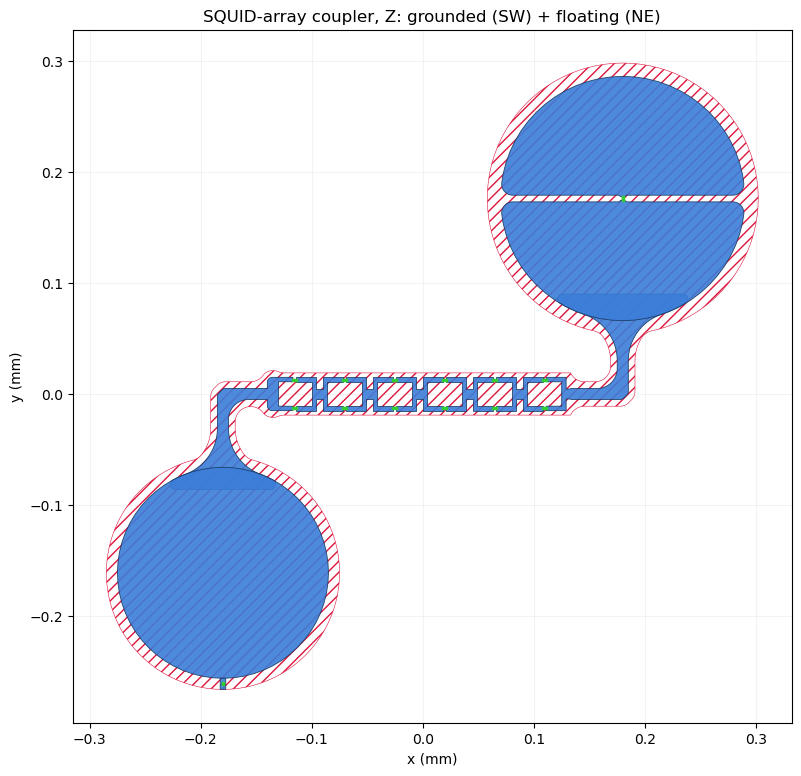

In [2]:
dz = coupled_pair(shape='Z')
sanity_checks(dz)
print('components:', list(dz.components.keys()))
print('junction rows:', len(dz.qgeometry.tables['junction']),
      '  (12 coupler + 1 grounded + 1 floating)')
show(dz, 'SQUID-array coupler, Z: grounded (SW) + floating (NE)')

`sanity_checks`: ground is **one** connected piece (no loop here, unlike the
ring design). The coupler's flare overlaps the grounded pad and one floating
half-island (`island_R`) by ~1500-2100 um^2 each -- a solid galvanic merge --
and never touches `island_L`, so the floating transmon is not shorted across
its junction.

### zoom: how each end merges onto its island

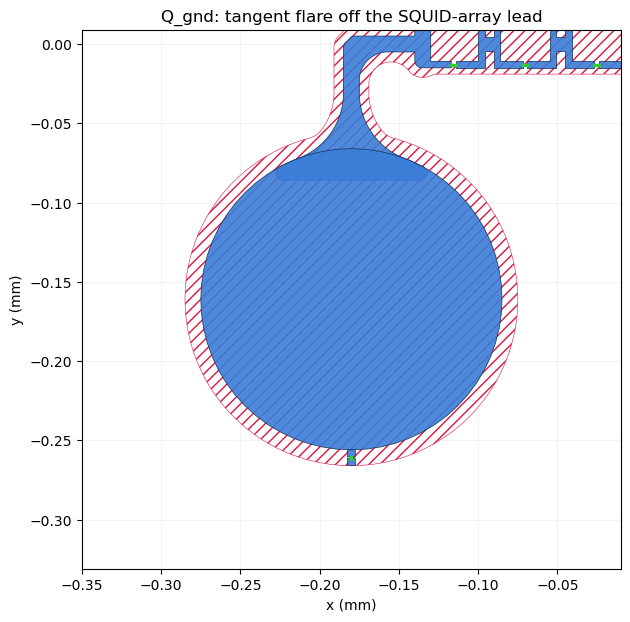

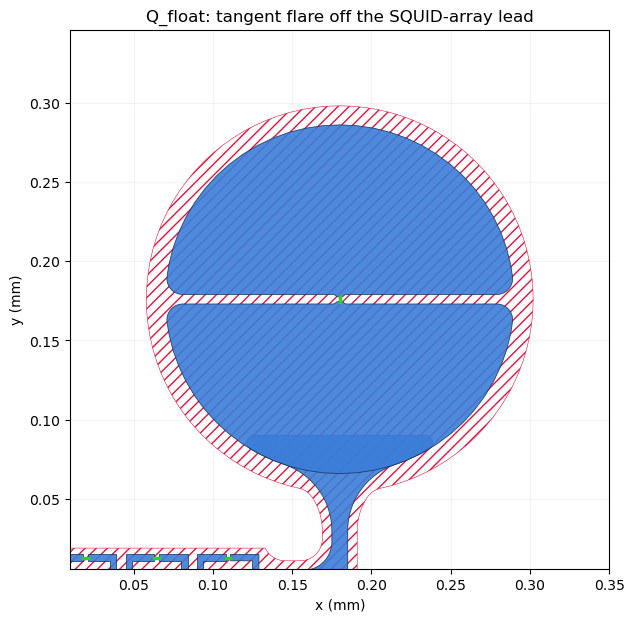

In [3]:
for nm in ('Q_gnd', 'Q_float'):
    q = dz.components[nm]
    cx = float(str(q.options['pos_x']).replace('um', '')) * 1e-3
    cy = float(str(q.options['pos_y']).replace('um', '')) * 1e-3
    show(dz, f'{nm}: tangent flare off the SQUID-array lead', figsize=(7, 7),
         xlim=(cx - 0.17, cx + 0.17), ylim=(cy - 0.17, cy + 0.17))

The grounded transmon's JJ (`jj_angle`) is auto-pointed 180 deg away from the
flare contact; the floating transmon's `orientation` is set so one half-island
arc faces the contact, keeping the split gap 90 deg clear.

## 2. The U pair

`shape='U'` -- both transmons on the same side, each lead dips down to the
array and back. Better when the two qubits sit in a row and everything else
is on the far side.

metal nets (>300 um2): 8   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


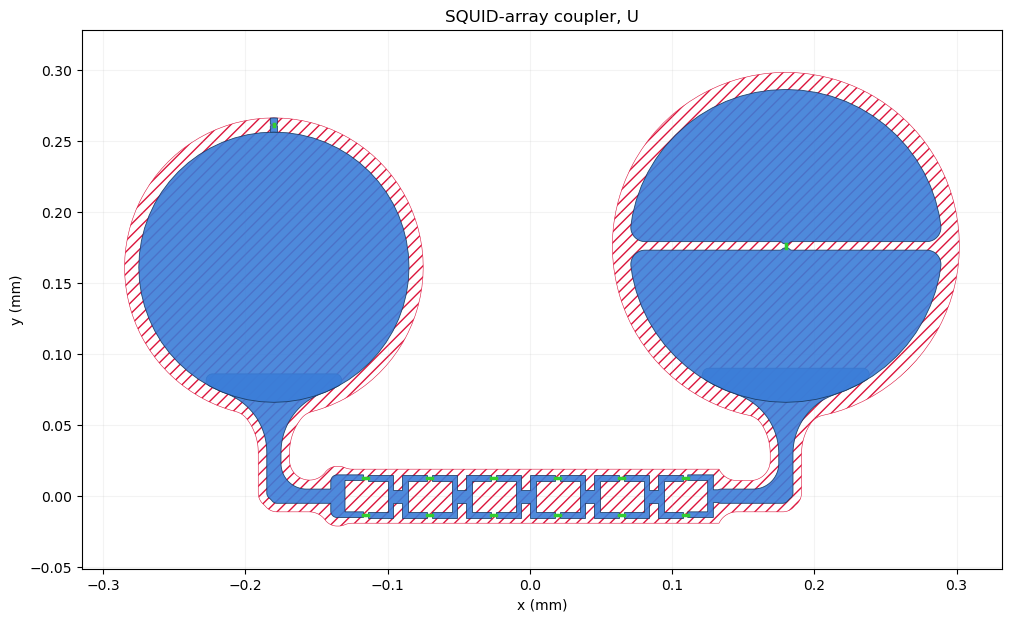

In [4]:
du = coupled_pair(shape='U')
sanity_checks(du)
show(du, 'SQUID-array coupler, U', figsize=(12, 7))

## 3. Arbitrary orientation + longer outward legs

`orientation_deg` rotates the whole coupler (the transmons follow, since they
are placed from `island_centers()`); `lead_out_um` / `lead_across_um` set how
far each end reaches out before turning in.

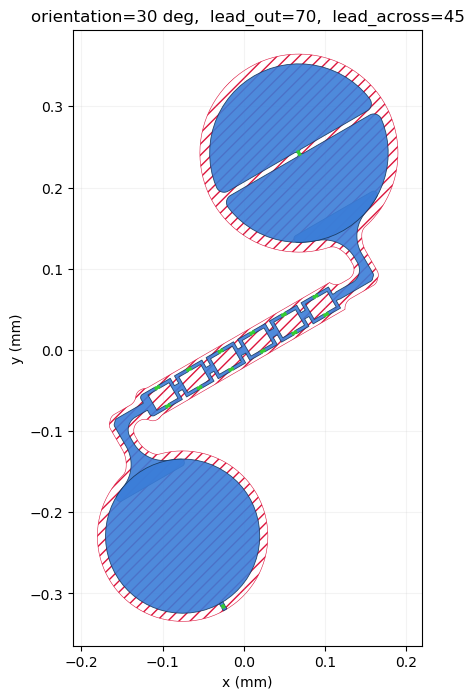

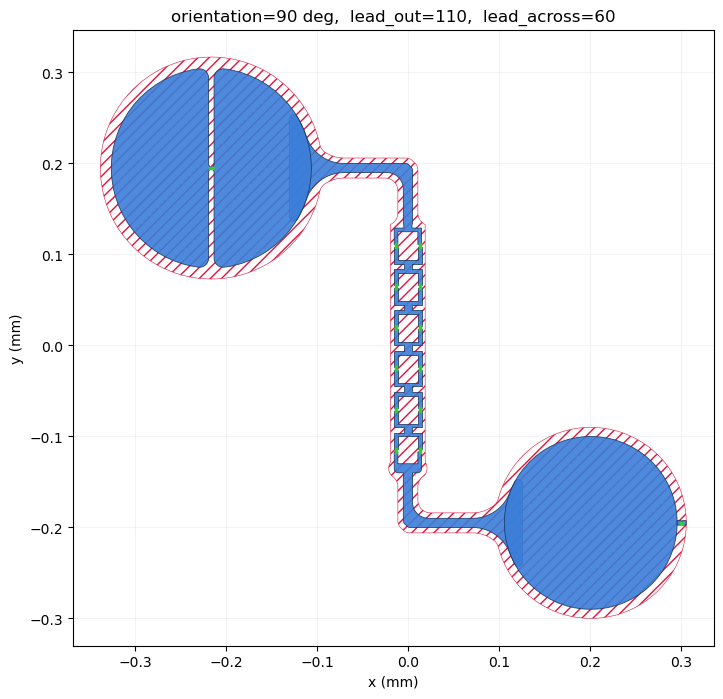

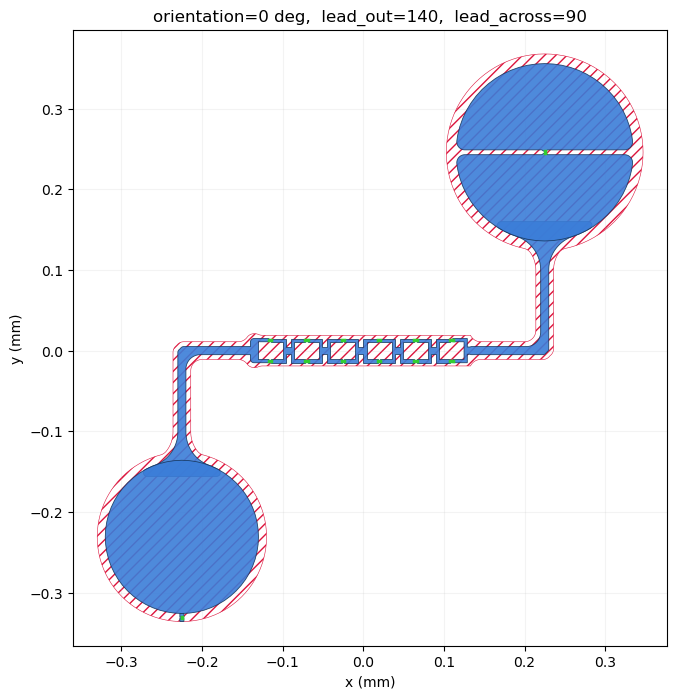

In [5]:
for ang, lo, la in [(30, 70, 45), (90, 110, 60), (0, 140, 90)]:
    d = coupled_pair(shape='Z', orientation_deg=ang, lead_out_um=lo, lead_across_um=la)
    show(d, f'orientation={ang} deg,  lead_out={lo},  lead_across={la}', figsize=(9, 8))

## 4. Junction ordering (for SQDMetal / Palace)

SQDMetal's `create_port_JosephsonJunction` addresses junctions on a component
**positionally** (insertion order into `design.qgeometry.tables['junction']`).
For the coupler alone the order is, per loop `i`: `jj_i_upper` then
`jj_i_lower`, so loop `i` -> junction indices `2*i` and `2*i+1`, and the
coupler carries `2 * n_squids` rows. Every gap is a real vacuum break and
**must** get a lumped inductive port, or the array's circulating current dies.
The transmon junctions come after, one row each.

In [6]:
jt = dz.qgeometry.tables['junction']
for i, (_, row) in enumerate(jt.iterrows()):
    comp = dz.components[[c for c in dz.components if dz.components[c].id == row['component']][0]]
    print(f"{i:2d}  {comp.name:14s} {row['name']:14s}  Lj={row['hfss_inductance']}")

 0  squid_coupler  jj_0_upper      Lj=10.0nH
 1  squid_coupler  jj_0_lower      Lj=10.0nH
 2  squid_coupler  jj_1_upper      Lj=10.0nH
 3  squid_coupler  jj_1_lower      Lj=10.0nH
 4  squid_coupler  jj_2_upper      Lj=10.0nH
 5  squid_coupler  jj_2_lower      Lj=10.0nH
 6  squid_coupler  jj_3_upper      Lj=10.0nH
 7  squid_coupler  jj_3_lower      Lj=10.0nH
 8  squid_coupler  jj_4_upper      Lj=10.0nH
 9  squid_coupler  jj_4_lower      Lj=10.0nH
10  squid_coupler  jj_5_upper      Lj=10.0nH
11  squid_coupler  jj_5_lower      Lj=10.0nH
12  Q_gnd          jj_object       Lj=11.0nH
13  Q_float        jj_object       Lj=12.0nH


## Interactive (MetalGUI)

Opens a **separate Qt window** (not inline). The `metal` logger is quieted
first (Qt platform warnings under an offscreen / forwarded display). Skip if
no display.

In [7]:
import os, logging
logging.getLogger('metal').setLevel(logging.ERROR)

_disp = os.environ.get('DISPLAY', '') or os.environ.get('WAYLAND_DISPLAY', '')
if _disp and os.environ.get('QT_QPA_PLATFORM') == 'offscreen':
    del os.environ['QT_QPA_PLATFORM']

if not _disp:
    print('[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots '
          'above already show the geometry.')
else:
    get_ipython().run_line_magic('gui', 'qt')
    from qiskit_metal import MetalGUI
    design = coupled_pair(shape='Z')
    gui = MetalGUI(design)
    gui.rebuild()
    gui.autoscale()

[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots above already show the geometry.
